# Совпадение слоев `base` и `oracle`, трансплантация слоев и внутренняя структура моделей

В проекте обучены 11 моделей одинаковой архитектуры на CIFAR-10: `full-baseline` (все 10 классов) и
`retain-oracle-c{0..9}` (все классы, кроме $c_{\text{forget}}$). `retain-oracle` - эталон того, какой должна
стать `full-baseline` после удаления класса $c_{\text{forget}}$.

Ноутбук отвечает на три вопроса:

1. Насколько совпадают слои `base` и `oracle` - послойно, в весовом пространстве и в пространстве
   активаций (CKA, соответствие нейронов)
2. Что будет, если перенести веса последних слоев из `oracle` в `base`

## Импорты

In [19]:
import copy
import hashlib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
import torch
import itertools
import torch.nn.functional as F
from tqdm import tqdm
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Final, override
from pydantic import BaseModel
import seaborn as sns
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED: int = 7
FORGET_CLASS: Final[int] = 0
BASELINE_FORGET_CLASS: Final[int] = 0


def set_seed(seed: int = SEED) -> None:
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)


set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.figsize": (12, 6),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 11,
    }
)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

## Модель и данные

Архитектура повторена из `learning.ipynb`.

In [2]:
class ConvolutionalModel(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features: nn.Module = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.head: nn.Module = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )

    @override
    def forward(self, input: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(input))


def build_model(state: dict[str, torch.Tensor]) -> ConvolutionalModel:
    model = ConvolutionalModel()
    model.load_state_dict({key: value.clone() for key, value in state.items()})
    model.eval()
    return model

### Загрузка 11 базовых моделей

Модели скачиваются вместе с метаданными обучения:
гиперпараметры + метрики по эпохам. Для каждой модели дополнительно считается sha256 файла весов — это
проверка, что все 11 моделей действительно разные и что сравнения не вырождены.

In [3]:
MODEL_ROOT: str = "ycalkk/convolutional-unlearning/pyTorch"
ORACLE_PREFIX: str = "retain-oracle-c"
CANDIDATES: list[int] = list(range(10))
CLASS_NAMES: list[str] = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]


class ModelMeta(BaseModel):
    model_type: str
    forget_class: int | None
    epochs: int
    learning_rate: float
    batch_size: int
    init_sha256: str
    seed: int
    metrics: list[dict[str, Any]]


@dataclass
class ModelData:
    name: str
    state: dict[str, torch.Tensor]
    meta: ModelMeta
    version_dir: Path

    @property
    def model(self) -> ConvolutionalModel:
        if self._model is None:
            self._model = build_model(self.state)
        return self._model

    _model: ConvolutionalModel | None = None


def get_model_data(name: str, handle: str) -> ModelData:
    version_dir = Path(kagglehub.model_download(handle))
    state = torch.load(
        version_dir / "weights.pt", map_location="cpu", weights_only=True
    )
    meta = ModelMeta.model_validate_json(
        (version_dir / "experiment_metadata.json").read_text(encoding="utf-8")
    )
    return ModelData(name=name, state=state, meta=meta, version_dir=version_dir)


MODELS: dict[str, ModelData] = {
    "baseline": get_model_data("baseline", f"{MODEL_ROOT}/full-baseline"),
    **{
        f"oracle-c{cls}": get_model_data(
            f"oracle-c{cls}", f"{MODEL_ROOT}/{ORACLE_PREFIX}{cls}"
        )
        for cls in CANDIDATES
    },
}
MODEL_NAMES: list[str] = list(MODELS)
FORGET_INDEX: dict[str, int] = {
    name: (
        BASELINE_FORGET_CLASS
        if data.meta.forget_class is None
        else data.meta.forget_class
    )
    for name, data in MODELS.items()
}
baseline: ModelData = MODELS["baseline"]
baseline_state: dict[str, torch.Tensor] = baseline.state

audit = pd.DataFrame(
    [
        {
            "model": name,
            "type": data.meta.model_type,
            "forget_class": data.meta.forget_class,
            "epochs": data.meta.epochs,
            "lr": data.meta.learning_rate,
            "batch_size": data.meta.batch_size,
            "init_sha256": data.meta.init_sha256,
            "seed": data.meta.seed,
            "weight_sha256": hashlib.sha256(
                (data.version_dir / "weights.pt").read_bytes()
            ).hexdigest()[:12],
        }
        for name, data in MODELS.items()
    ]
).set_index("model")
audit

,type,forget_class,epochs,lr,batch_size,init_sha256,seed,weight_sha256
model,,,,,,,,
baseline,full_baseline,NaN,30,0.001,128,b4b16b6c6fd1beec,7,2e88b82a4e93
oracle-c0,retain_oracle,0.0,30,0.001,128,b4b16b6c6fd1beec,7,7830cc12efc1
oracle-c1,retain_oracle,1.0,30,0.001,128,b4b16b6c6fd1beec,7,e9b0ffa8966a
oracle-c2,retain_oracle,2.0,30,0.001,128,b4b16b6c6fd1beec,7,a35abc186443
oracle-c3,retain_oracle,3.0,30,0.001,128,b4b16b6c6fd1beec,7,7b18130c0c7e
oracle-c4,retain_oracle,4.0,30,0.001,128,b4b16b6c6fd1beec,7,5b899d97baf4
oracle-c5,retain_oracle,5.0,30,0.001,128,b4b16b6c6fd1beec,7,0e1e5f049a71
oracle-c6,retain_oracle,6.0,30,0.001,128,b4b16b6c6fd1beec,7,b54ee554ca3d
oracle-c7,retain_oracle,7.0,30,0.001,128,b4b16b6c6fd1beec,7,b932754facc1


### Тестовая выборка и метрики

Все модели оцениваются на одном и том же полном тесте CIFAR-10 с тем же препроцессингом, что и при обучении.

In [4]:
dataset_path = kagglehub.dataset_download("pankrzysiu/cifar10-python")
default_transform = [
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
]

test_raw = datasets.CIFAR10(
    root=dataset_path,
    train=False,
    transform=transforms.Compose(default_transform),
)
train_raw = datasets.CIFAR10(
    root=dataset_path,
    train=True,
    transform=transforms.Compose(
        [
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            *default_transform,
        ]
    ),
)
train_raw_deterministic = datasets.CIFAR10(
    root=dataset_path,
    train=True,
    transform=transforms.Compose(default_transform),
)

test_targets = np.array(test_raw.targets)
test_loader = DataLoader(test_raw, batch_size=256, shuffle=False)
retain_mask = test_targets != FORGET_CLASS
print(
    f"Тест: {len(test_raw)} объектов, retain {retain_mask.sum()}, forget {(~retain_mask).sum()}"
)

Тест: 10000 объектов, retain 9000, forget 1000


In [5]:
@dataclass
class Evaluation:
    name: str
    probability: npt.NDArray[np.float64]
    prediction: npt.NDArray[np.int64]
    target: npt.NDArray[np.int64]

    def accuracy(self, classes: npt.ArrayLike | None = None) -> float:
        if classes is None:
            return float(np.mean(self.prediction == self.target))
        mask = np.isin(self.target, np.asarray(classes))
        return float(np.mean(self.prediction[mask] == self.target[mask]))

    def class_accuracy(self, cls: int) -> float:
        return self.accuracy([cls])

    def class_confidence(self, cls: int) -> float:
        return float(np.mean(self.probability[self.target == cls, cls]))

    def class_entropy(self, cls: int) -> float:
        probability = self.probability[self.target == cls]
        return float(
            np.mean(-np.sum(probability * np.log(probability + 1e-12), axis=1))
        )

    def class_max_confidence(self, cls: int) -> float:
        return float(np.mean(self.probability[self.target == cls].max(axis=1)))

    def class_prediction_distribution(self, cls: int) -> npt.NDArray[np.float64]:
        counts = np.bincount(self.prediction[self.target == cls], minlength=10).astype(
            np.float64
        )
        return counts / counts.sum()


@torch.no_grad()
def collect_logits(model: nn.Module, loader: DataLoader[Any]) -> torch.Tensor:
    chunks = []
    for x, _ in loader:
        chunks.append(model(x.to(device)).cpu())
    return torch.cat(chunks)


def build_evaluation(name: str, logits: torch.Tensor) -> Evaluation:
    probability = torch.softmax(logits.float(), dim=-1).numpy().astype(np.float64)
    return Evaluation(
        name=name,
        probability=probability,
        prediction=logits.argmax(dim=-1).numpy().astype(np.int64),
        target=test_targets.astype(np.int64),
    )


def evaluate_model(name: str, model: nn.Module) -> Evaluation:
    return build_evaluation(name, collect_logits(model, test_loader))

Перед экспериментами сверка с метаданными: пересчет метрик на полном тесте должен в точности совпасть
с последней эпохой обучения из `experiment_metadata.json`. Это проверка, что веса и препроцессинг
воспроизводятся корректно. Метрики каждого оракула считаются относительно его собственного забытого класса (для `baseline` это класс 0), поэтому `retain_accuracy` не включает его класс, а `confidence_forget_class` всегда про свой класс.

In [6]:
@dataclass
class EvaluationSummary:
    name: str
    accuracy: float
    retain_accuracy: float
    accuracy_forget_class: float
    confidence_forget_class: float
    max_confidence_forget_class: float
    entropy_forget_class: float
    collapse_class: int
    collapse_share: float


def summarize(
    evaluation: Evaluation, forget_class: int = FORGET_CLASS
) -> EvaluationSummary:
    distribution = evaluation.class_prediction_distribution(forget_class)
    distribution = distribution.copy()
    distribution[forget_class] = 0.0
    collapse_class = int(np.argmax(distribution))
    retain = [cls for cls in range(10) if cls != forget_class]
    return EvaluationSummary(
        name=evaluation.name,
        accuracy=evaluation.accuracy(),
        retain_accuracy=evaluation.accuracy(retain),
        accuracy_forget_class=evaluation.class_accuracy(forget_class),
        confidence_forget_class=evaluation.class_confidence(forget_class),
        max_confidence_forget_class=evaluation.class_max_confidence(forget_class),
        entropy_forget_class=evaluation.class_entropy(forget_class),
        collapse_class=collapse_class,
        collapse_share=float(distribution[collapse_class]),
    )


evaluations: dict[str, Evaluation] = {
    name: evaluate_model(name, data.model) for name, data in tqdm(MODELS.items())
}

sanity_rows: list[dict[str, Any]] = []
for name, data in MODELS.items():
    sanity_rows.append(
        {
            "model": name,
            "accuracy": evaluations[name].accuracy(),
            "accuracy_meta": data.meta.metrics[-1]["full_test_accuracy"],
            "p_forget": float(
                np.mean(evaluations[name].probability[:, FORGET_INDEX[name]])
            ),
            "p_forget_meta": data.meta.metrics[-1][
                "full_test_forget_class_probability"
            ],
        }
    )
sanity = pd.DataFrame(sanity_rows).set_index("model")
sanity["accuracy_delta"] = sanity["accuracy"] - sanity["accuracy_meta"]
sanity["p_forget_delta"] = sanity["p_forget"] - sanity["p_forget_meta"]

assert np.allclose(sanity["accuracy_delta"], 0.0, atol=1e-6), (
    "accuracy не сошлась с метаданными"
)
assert np.allclose(sanity["p_forget_delta"], 0.0, atol=1e-6), (
    "вероятности не сошлись с метаданными"
)

summaries = {
    name: summarize(evaluation, forget_class=FORGET_INDEX[name])
    for name, evaluation in evaluations.items()
}
reference = pd.DataFrame([vars(summary) for summary in summaries.values()]).set_index(
    "name"
)
reference["collapse_class"] = reference["collapse_class"].map(
    dict(enumerate(CLASS_NAMES))  # pyright: ignore[reportArgumentType]
)
reference

100%|██████████| 11/11 [02:01<00:00, 11.00s/it]


,accuracy,retain_accuracy,accuracy_forget_class,confidence_forget_class,max_confidence_forget_class,entropy_forget_class,collapse_class,collapse_share
name,,,,,,,,
baseline,0.8349,0.829778,0.881,8.186540e-01,0.870398,0.379382,ship,0.033
oracle-c0,0.7605,0.845000,0.000,1.696771e-06,0.745995,0.697911,bird,0.348
oracle-c1,0.7521,0.835667,0.000,2.611618e-06,0.807476,0.513895,truck,0.696
oracle-c2,0.7731,0.859000,0.000,3.299737e-06,0.680870,0.860371,deer,0.221
oracle-c3,0.7890,0.876667,0.000,1.143941e-06,0.715618,0.767490,dog,0.522
oracle-c4,0.7665,0.851667,0.000,4.978008e-07,0.643498,0.930240,bird,0.342
oracle-c5,0.7755,0.861667,0.000,7.351963e-07,0.743379,0.689447,cat,0.611
oracle-c6,0.7568,0.840889,0.000,1.039591e-06,0.664260,0.874270,cat,0.406
oracle-c7,0.7601,0.844556,0.000,1.054399e-06,0.670265,0.868124,deer,0.397


## Совпадение слоев в весовом пространстве

Сравниваем тензоры `base` и `oracle` попарно: относительное $L_2$-расстояние
$\frac{\Vert{}W_{\text{oracle}} - W_{\text{base}}\Vert{}_2}{\Vert{}W_{\text{base}}\Vert{}_2}$ и косинус между
векторизованными тензорами. Если слои совпадают, ожидаем малое $L_2$ и косинус, близкий к единице.

Тензоры группируются в стадии - от выхода к входу:

| стадия | тензоры |
| :--- | :--- |
| `S1_logits` | `head.4.*` (финальный линейный слой, 128→10) |
| `S2_embedding` | `head.1.*` (линейный слой 2048→128) |
| `S3_block3` | `features.8.*` (conv 64→128) + `features.9.*` (BatchNorm) |
| `S4_block2` | `features.4.*` + `features.5.*` |
| `S5_block1` | `features.0.*` + `features.1.*` |

Стадии дальше используются и как единицы трансплантации.

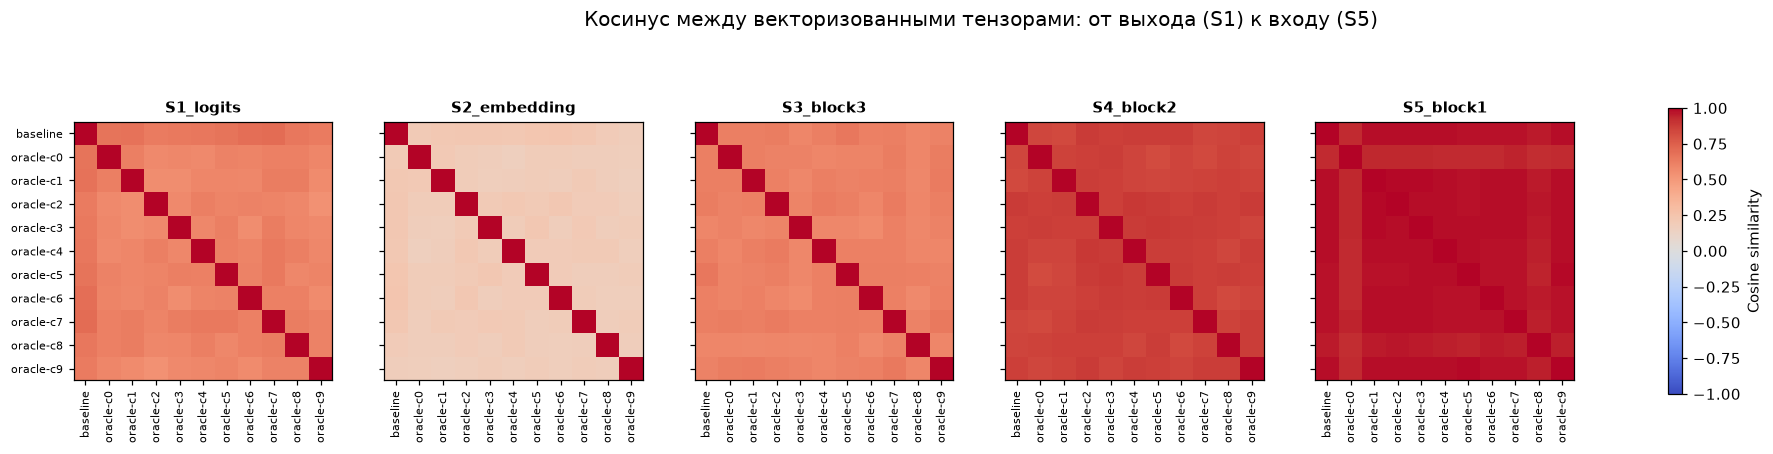

Косинус между векторизованными тензорами относительно baseline:


,S1_logits,S2_embedding,S3_block3,S4_block2,S5_block1
oracle-c0,0.665776,0.197654,0.620365,0.837935,0.924883
oracle-c1,0.674592,0.211508,0.621730,0.834362,0.982583
oracle-c2,0.633685,0.221183,0.626934,0.876591,0.981243
oracle-c3,0.642386,0.221163,0.593395,0.864693,0.981262
oracle-c4,0.652734,0.216494,0.618873,0.869008,0.979711
oracle-c5,0.665091,0.227857,0.656086,0.873489,0.970248
oracle-c6,0.687557,0.240323,0.611535,0.870309,0.975785
oracle-c7,0.695364,0.224053,0.618095,0.842048,0.972340
oracle-c8,0.655585,0.188406,0.586727,0.849476,0.958655
oracle-c9,0.635807,0.171966,0.602101,0.860269,0.978221


In [7]:
STAGE_KEYS: dict[str, list[str]] = {
    "S1_logits": ["head.4.weight", "head.4.bias"],
    "S2_embedding": ["head.1.weight", "head.1.bias"],
    "S3_block3": [
        "features.8.weight",
        "features.8.bias",
        "features.9.weight",
        "features.9.bias",
        "features.9.running_mean",
        "features.9.running_var",
    ],
    "S4_block2": [
        "features.4.weight",
        "features.4.bias",
        "features.5.weight",
        "features.5.bias",
        "features.5.running_mean",
        "features.5.running_var",
    ],
    "S5_block1": [
        "features.0.weight",
        "features.0.bias",
        "features.1.weight",
        "features.1.bias",
        "features.1.running_mean",
        "features.1.running_var",
    ],
}
STAGE_ORDER: list[str] = [
    "S1_logits",
    "S2_embedding",
    "S3_block3",
    "S4_block2",
    "S5_block1",
]
LEARNABLE_STAGES: dict[str, list[str]] = {
    "features_conv1": ["features.0.weight", "features.0.bias"],
    "features_bn1": [
        "features.1.weight",
        "features.1.bias",
        "features.1.running_mean",
        "features.1.running_var",
    ],
    "features_conv2": ["features.4.weight", "features.4.bias"],
    "features_bn2": [
        "features.5.weight",
        "features.5.bias",
        "features.5.running_mean",
        "features.5.running_var",
    ],
    "features_conv3": ["features.8.weight", "features.8.bias"],
    "features_bn3": [
        "features.9.weight",
        "features.9.bias",
        "features.9.running_mean",
        "features.9.running_var",
    ],
    "head_1": ["head.1.weight", "head.1.bias"],
    "head_4": ["head.4.weight", "head.4.bias"],
}

stage_cosine_matrices: dict[str, Any] = {}
base_idx = MODEL_NAMES.index("baseline")
stage_profiles = []

for stage_name, keys in STAGE_KEYS.items():
    vectors = torch.stack(
        [
            torch.cat([MODELS[m].state[k].float().flatten() for k in keys])
            for m in MODEL_NAMES
        ]
    )
    normed = F.normalize(vectors, dim=1)
    cos_matrix = (normed @ normed.T).cpu().numpy()
    stage_cosine_matrices[stage_name] = cos_matrix

    stage_profiles.append(cos_matrix[base_idx])

df_profile = pd.DataFrame(
    np.array(stage_profiles).T, index=MODEL_NAMES, columns=list(STAGE_KEYS.keys())
).drop(index="baseline")

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)
for ax, (stage_name, matrix) in zip(axes, stage_cosine_matrices.items()):
    im = ax.imshow(matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0)
    if stage_name == "S5_block1":
        fig.colorbar(
            im, ax=axes.ravel().tolist(), shrink=0.75, label="Cosine similarity"
        )
    ax.set_title(stage_name, fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(MODEL_NAMES)))
    ax.set_xticklabels(MODEL_NAMES, rotation=90, fontsize=7)
    ax.grid(False)

axes[0].set_yticks(range(len(MODEL_NAMES)))
axes[0].set_yticklabels(MODEL_NAMES, fontsize=7)

fig.suptitle(
    "Косинус между векторизованными тензорами: от выхода (S1) к входу (S5)", fontsize=13
)
plt.show()
print("Косинус между векторизованными тензорами относительно baseline:")
df_profile

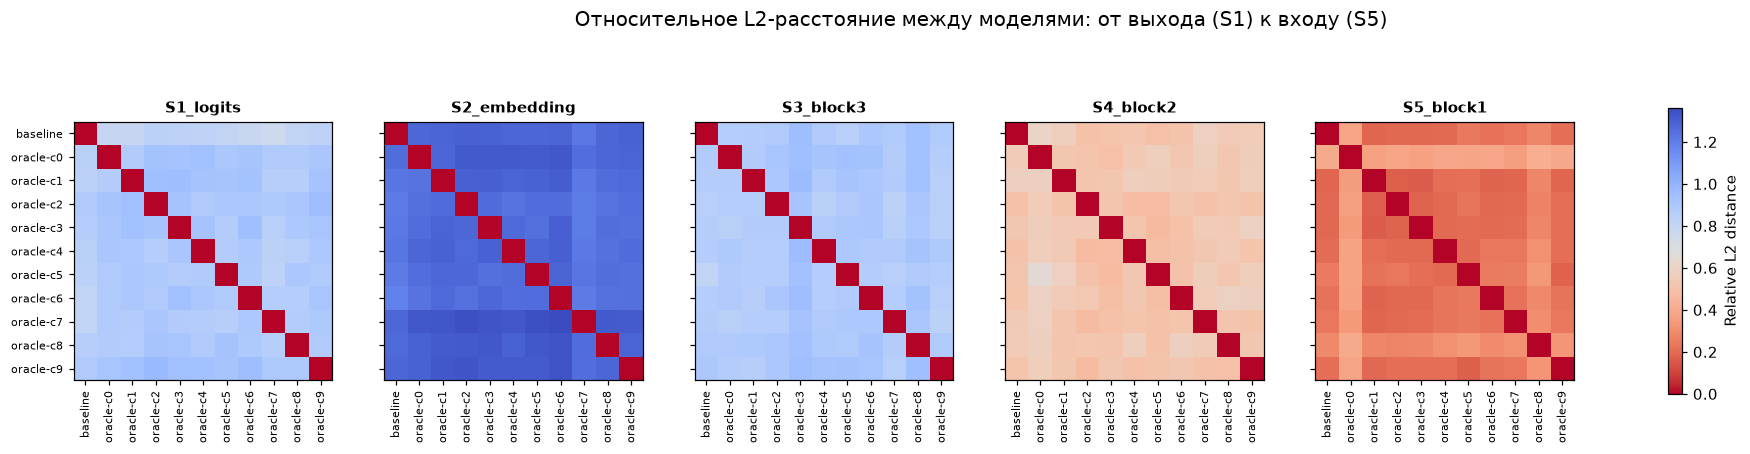

Относительное L2-расстояние относительно baseline:


,S1_logits,S2_embedding,S3_block3,S4_block2,S5_block1
oracle-c0,0.8474,1.2575,0.8765,0.5512,0.4010
oracle-c1,0.8339,1.2275,0.8701,0.5780,0.1867
oracle-c2,0.8798,1.2073,0.8459,0.4948,0.1936
oracle-c3,0.8652,1.2128,0.8658,0.5315,0.1933
oracle-c4,0.8456,1.2260,0.8654,0.5039,0.2037
oracle-c5,0.8356,1.2082,0.8090,0.5159,0.2487
oracle-c6,0.8048,1.1869,0.8635,0.5135,0.2196
oracle-c7,0.8126,1.2719,0.8693,0.5477,0.2346
oracle-c8,0.8583,1.2708,0.8872,0.5479,0.2899
oracle-c9,0.8877,1.2816,0.9005,0.5146,0.2098


In [8]:
stage_l2_matrices: dict[str, np.ndarray] = {}
base_idx = MODEL_NAMES.index("baseline")
stage_profiles = []

for stage_name, keys in STAGE_KEYS.items():
    vectors = torch.stack(
        [
            torch.cat([MODELS[m].state[k].float().flatten() for k in keys])
            for m in MODEL_NAMES
        ]
    )

    l2_dist = torch.cdist(vectors, vectors, p=2.0)

    norms = torch.norm(vectors, dim=1, keepdim=True)
    rel_l2_matrix = (l2_dist / norms.T).cpu().numpy()
    stage_l2_matrices[stage_name] = rel_l2_matrix

    stage_profiles.append(rel_l2_matrix[:, base_idx])

df_profile_l2 = pd.DataFrame(
    np.array(stage_profiles).T, index=MODEL_NAMES, columns=list(STAGE_KEYS.keys())
).drop(index="baseline")

max_val = max(mat.max() for mat in stage_l2_matrices.values())

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)
for ax, (stage_name, matrix) in zip(axes, stage_l2_matrices.items()):
    im = ax.imshow(matrix, cmap="coolwarm_r", vmin=0.0, vmax=max_val)
    ax.set_title(stage_name, fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(MODEL_NAMES)))
    ax.set_xticklabels(MODEL_NAMES, rotation=90, fontsize=7)
    ax.grid(False)

axes[0].set_yticks(range(len(MODEL_NAMES)))
axes[0].set_yticklabels(MODEL_NAMES, fontsize=7)

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.75, label="Relative L2 distance")
fig.suptitle(
    "Относительное L2-расстояние между моделями: от выхода (S1) к входу (S5)",
    fontsize=13,
)
plt.show()

print("Относительное L2-расстояние относительно baseline:")
display(df_profile_l2.round(4))

Можно увидеть тенденцию, что чем ближе к выходу тем больше различий между моделями. Например, косинус между тензорами на первом входном слое в среднем $\approx 0.97$, а на предпоследнем линейном слое модели $\approx 0.21$.

### Есть ли в весовых расстояниях сигнал об удаленном классе?

Проверим гипотезу: отражает ли положение весов в пространстве параметров семантику классов.
Если веса моделей действительно кодируют смысл данных, то геометрия пространства весов должна подчиняться двум законам:
1) Базовая модель иногда путает автомобиль и грузовик: у них общие фильтры (колеса, фары, асфальт). Если обучить сеть без автомобилей (`oracle-c1`), ей все равно придется выучить колеса и фары ради грузовиков. Если обучить сеть без грузовиков (`oracle-c9`), ей тоже придется выучить колеса и фары ради автомобилей $\Rightarrow$ веса `oracle-c1` и `oracle-c9` должны оказаться близко друг к другу в пространстве параметров. Но если взять далекие классы, например, самолет и лягушка, то удаление самолета убирает фильтры крыльев и синего неба, а удаление лягушки убирает лапы и текстуру кожи - общих признаков мало, поэтому `oracle-c0` и `oracle-c6` должны разойтись далеко. Поэтому должны наблюдать, что чем сильнее базовая модель путает классы $i$ и $j$, тем меньше должно быть весовое расстояние между `oracle-ci` и `oracle-cj`.
2) Между `baseline` и любым оракулом выборка отличается ровно на 1 класс (90% общих картинок), а между двумя оракулами (`oracle-ci` и `oracle-cj`) выборки отличаются на 2 класса (80% общих картинок - в одном нет класса $i$, в другом нет класса $j$). `baseline` должен быть центроидом и расстояние от baseline до любого оракула должно быть меньше, чем расстояние между двумя оракулами: $$d(W_{\text{base}}, W_{\text{oracle}-i}) < d(W_{\text{oracle}-i}, W_{\text{oracle}-j})$$

Корреляция весового расстояния с путаницей классов:


,spearman_rho,mean_oracle_distance
S1_logits,-0.1455,0.8980
S2_embedding,-0.3293,1.2780
S3_block3,-0.0057,0.8886
S4_block2,-0.3326,0.5297
S5_block1,-0.0261,0.2576


Контроль расстояний (должно быть Base-Oracle < Oracle-Oracle)


,"d(baseline, oracle)","d(oracle, oracle)",base_closer,diff
stage,,,,
S1_logits,0.8471,0.8980,True,0.0509
S2_embedding,1.2352,1.2780,True,0.0428
S3_block3,0.8653,0.8886,True,0.0233
S4_block2,0.5299,0.5297,False,-0.0002
S5_block1,0.2381,0.2576,True,0.0195


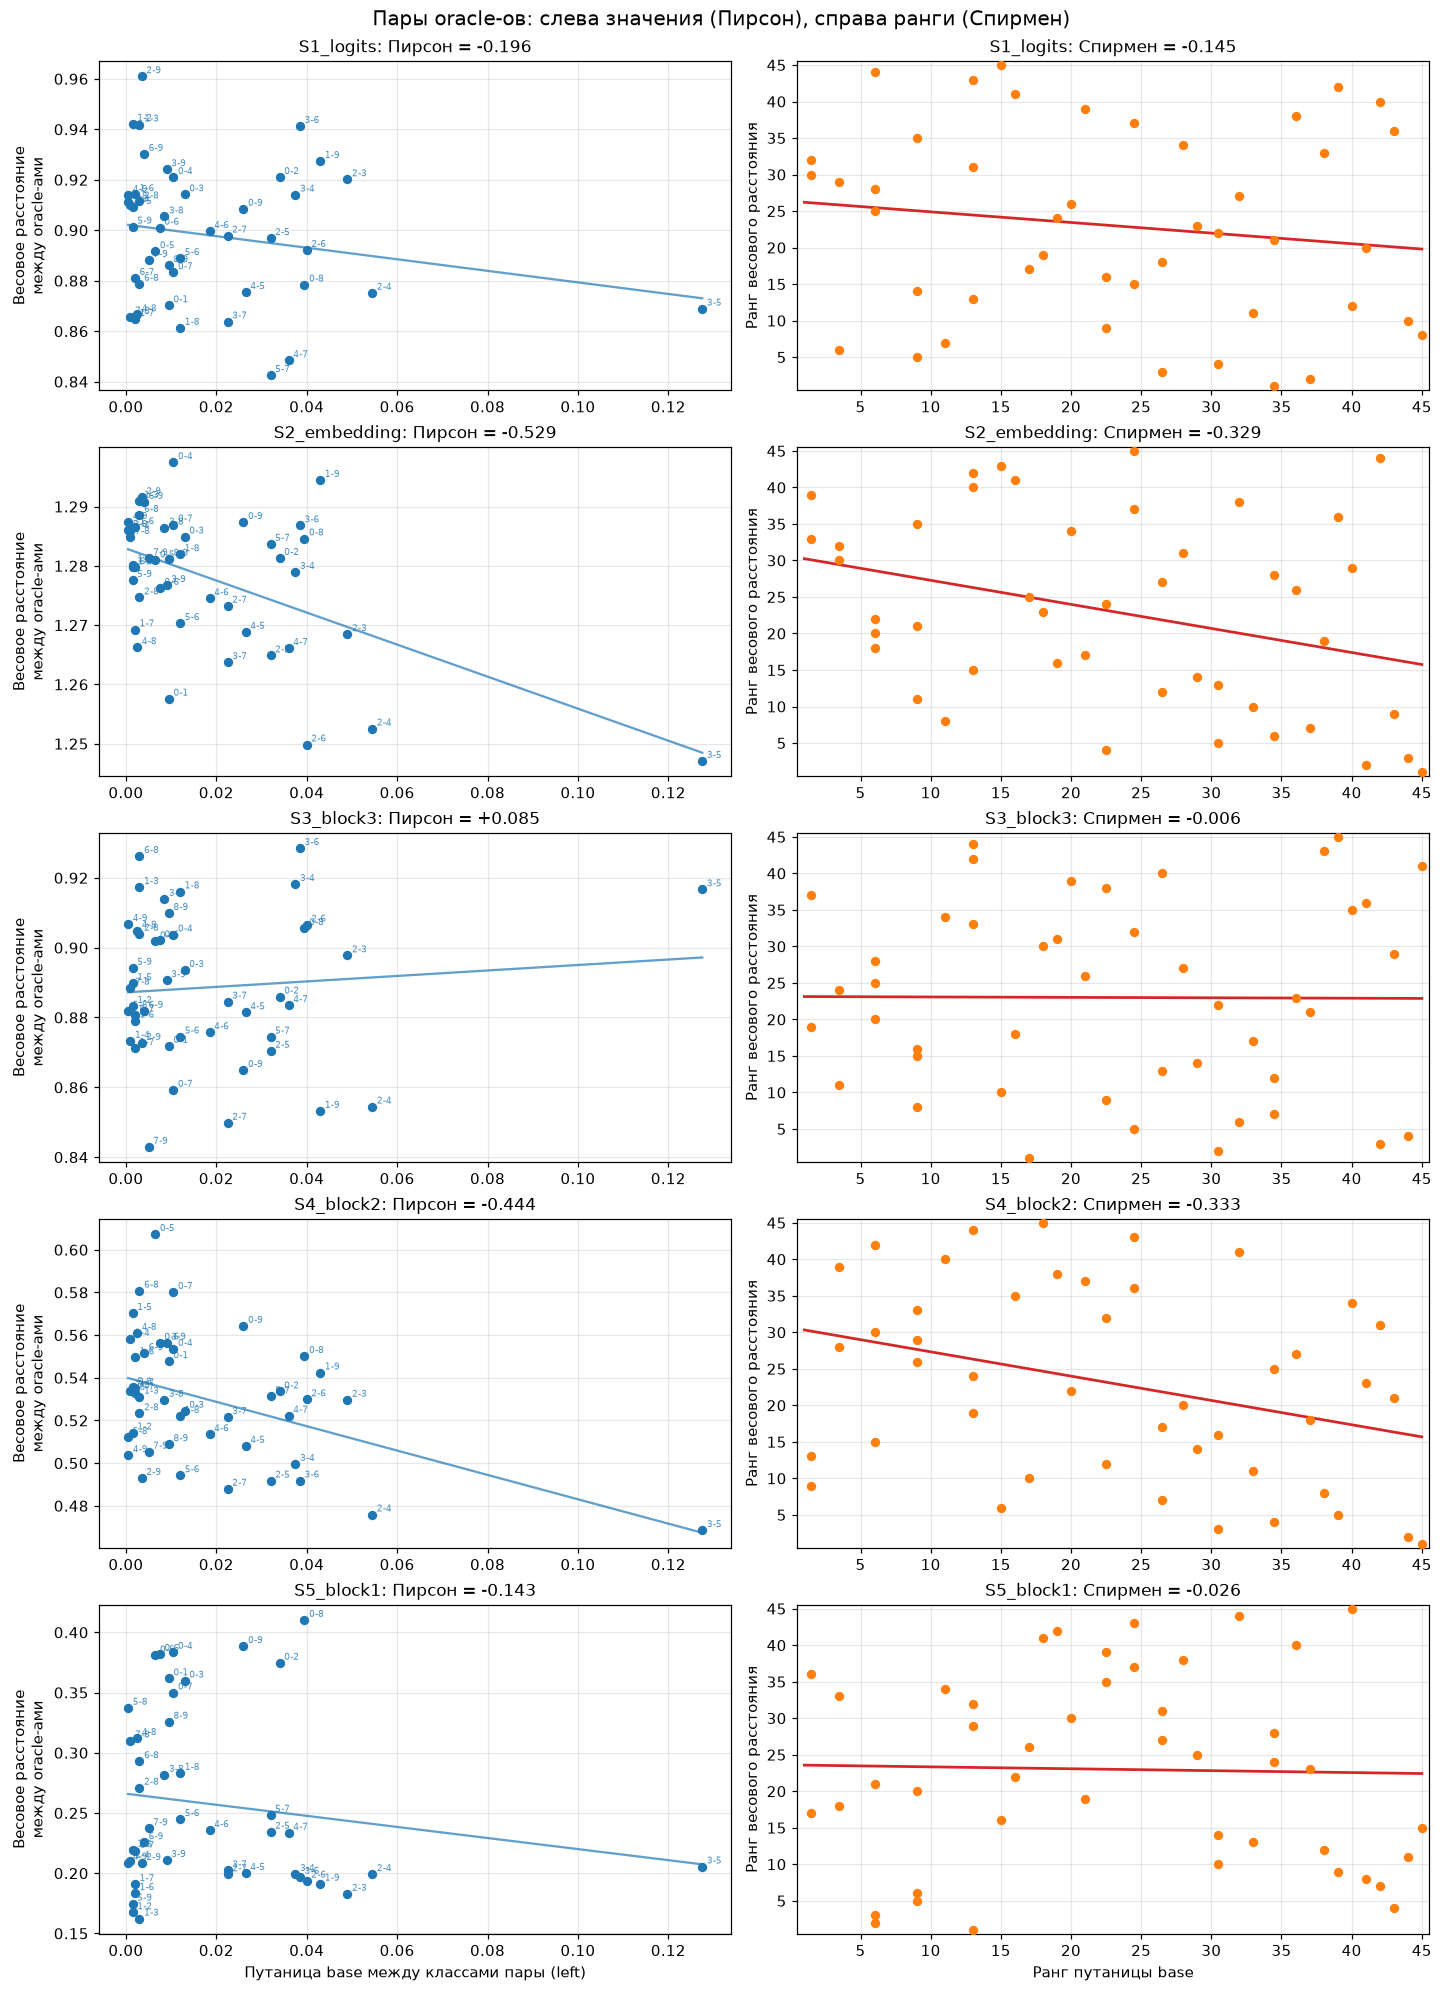

In [9]:
base_eval = evaluations["baseline"]
raw_conf = np.zeros((10, 10))
for c in range(10):
    raw_conf[c] = base_eval.class_prediction_distribution(c)

mutual_confusion = (raw_conf + raw_conf.T) / 2.0

pairs = list(itertools.combinations(range(10), 2))
confusion_vector = np.array([mutual_confusion[i, j] for i, j in pairs])

stage_correlations = {}
stage_distances: dict[str, npt.NDArray[np.float64]] = {}


def spearman_rank_correlation(left: npt.ArrayLike, right: npt.ArrayLike) -> float:
    a = np.asarray(left, dtype=np.float64)
    b = np.asarray(right, dtype=np.float64)
    rank_a = pd.Series(a).rank().to_numpy()
    rank_b = pd.Series(b).rank().to_numpy()
    return float(np.corrcoef(rank_a, rank_b)[0, 1])


for stage_name, keys in STAGE_KEYS.items():
    oracle_vecs = {
        cls: torch.cat(
            [MODELS[f"oracle-c{cls}"].state[k].float().flatten() for k in keys]
        )
        for cls in range(10)
    }

    dist_vector = []
    for i, j in pairs:
        vi, vj = oracle_vecs[i], oracle_vecs[j]
        rel_dist = float((vi - vj).norm() / (0.5 * (vi.norm() + vj.norm())))
        dist_vector.append(rel_dist)

    dist_vector = np.array(dist_vector)
    stage_distances[stage_name] = dist_vector
    corr = spearman_rank_correlation(confusion_vector, dist_vector)
    stage_correlations[stage_name] = {
        "spearman_rho": corr,
        "mean_oracle_distance": float(dist_vector.mean()),
    }

df_signal = pd.DataFrame(stage_correlations).T
print("Корреляция весового расстояния с путаницей классов:")
display(df_signal.round(4))

centrality_rows = []

for stage_name, keys in STAGE_KEYS.items():
    base_v = torch.cat([MODELS["baseline"].state[k].float().flatten() for k in keys])
    oracle_vecs = [
        torch.cat([MODELS[f"oracle-c{cls}"].state[k].float().flatten() for k in keys])
        for cls in range(10)
    ]

    base_to_oracle = [float((base_v - ov).norm() / base_v.norm()) for ov in oracle_vecs]

    oracle_to_oracle = [
        float(
            (oracle_vecs[i] - oracle_vecs[j]).norm()
            / (0.5 * (oracle_vecs[i].norm() + oracle_vecs[j].norm()))
        )
        for i, j in pairs
    ]

    centrality_rows.append(
        {
            "stage": stage_name,
            "d(baseline, oracle)": np.mean(base_to_oracle),
            "d(oracle, oracle)": np.mean(oracle_to_oracle),
            "base_closer": np.mean(base_to_oracle) < np.mean(oracle_to_oracle),
            "diff": np.mean(oracle_to_oracle) - np.mean(base_to_oracle),
        }
    )

df_centrality = pd.DataFrame(centrality_rows).set_index("stage")
print("Контроль расстояний (должно быть Base-Oracle < Oracle-Oracle)")
display(df_centrality.round(4))
rank_confusion = pd.Series(confusion_vector).rank().to_numpy()

fig, axes = plt.subplots(
    len(STAGE_ORDER), 2, figsize=(13, 3.6 * len(STAGE_ORDER)), constrained_layout=True
)
for row, stage_name in enumerate(STAGE_ORDER):
    distances = stage_distances[stage_name]
    rank_distance = pd.Series(distances).rank().to_numpy()
    rho = stage_correlations[stage_name]["spearman_rho"]
    pearson = float(np.corrcoef(confusion_vector, distances)[0, 1])

    ax = axes[row, 0]
    ax.scatter(confusion_vector, distances, s=26, color="tab:blue", zorder=3)
    for index, (i, j) in enumerate(pairs):
        ax.annotate(
            f"{i}-{j}",
            (confusion_vector[index], distances[index]),
            fontsize=6,
            color="tab:blue",
            alpha=0.8,
            xytext=(3, 2),
            textcoords="offset points",
        )
    slope = pearson * distances.std() / confusion_vector.std()
    line_x = np.array([confusion_vector.min(), confusion_vector.max()])
    ax.plot(
        line_x,
        distances.mean() + slope * (line_x - confusion_vector.mean()),
        color="tab:blue",
        linewidth=1.5,
        alpha=0.7,
    )
    ax.set_title(f"{stage_name}: Пирсон = {pearson:+.3f}")
    ax.set_ylabel("Весовое расстояние\nмежду oracle-ами")

    ax = axes[row, 1]
    ax.scatter(rank_confusion, rank_distance, s=26, color="tab:orange", zorder=3)
    rank_slope = rho * rank_distance.std() / rank_confusion.std()
    line_rank_x = np.array([1, len(pairs)])
    line_rank_y = rank_distance.mean() + rank_slope * (
        line_rank_x - rank_confusion.mean()
    )
    ax.plot(
        line_rank_x,
        line_rank_y,
        color="tab:red",
        linewidth=1.8,
    )
    ax.set_xlim(0.5, len(pairs) + 0.5)
    ax.set_ylim(0.5, len(pairs) + 0.5)
    ax.set_title(f"{stage_name}: Спирмен = {rho:+.3f}")
    ax.set_ylabel("Ранг весового расстояния")

axes[-1, 0].set_xlabel("Путаница base между классами пары (left)")
axes[-1, 1].set_xlabel("Ранг путаницы base")
fig.suptitle(
    "Пары oracle-ов: слева значения (Пирсон), справа ранги (Спирмен)", fontsize=13
)
plt.show()

Высокая отрицательная корреляция Спирмена ($\rho \approx -0.33$) на стадиях `S4_block2` и `S2_embedding` показывает: чем сильнее базовая модель путает классы $i$ и $j$, тем ближе в пространстве весов оказываются оракулы `oracle-ci` и `oracle-cj`.

`S5_block1` ($\rho = -0.0261$, дистанция $0.2576$): первый сверточный слой универсален и не зависит от семантики удаленного класса.

`S3_block3` ($\rho = -0.0057$, дистанция $0.8886$): корреляция с путаницей классов отсутствует при высокой дистанции между оракулами. Возникает разрыв: сигнал виден на $S4$ и $S2$, но исчезает на промежуточном $S3$.

Для стадий $S1, S2, S3, S5$ условие $d(W_{\text{base}}, W_{\text{oracle}-i}) < d(W_{\text{oracle}-i}, W_{\text{oracle}-j})$ выполняется. Сдвиг обучающей выборки на $1$ класс (удаление $c$, сохранение 90% данных) смещает веса слабее, чем сдвиг на 2 класса.

## Функциональное совпадение: CKA и соответствие нейронов

Весовые метрики дают топологию чекпоинтов, но не дают ответа на вопрос о вычислительной функции сети. Переход к CKA решает это ограничение:
1) В `S3_block3` веса разошлись ($\text{rel\_dist} \approx 0.89$), а семантическая корреляция исчезла ($\rho \approx 0$). Слой $S3$ окружен Batch Normalization и, возможно, он компенсировал это расхождение, тогда CKA покажет действительно разошлись представления, или $S3$ выполняет ту же функцию, но в другом численном масштабе.
2) В $S2$ относительное расстояние составляет $1.278$ - векторы весов разных оракулов почти ортогональны. Это может означать ортогональное вращение координатных осей. CKA инвариантна к ортогональным преобразованиям: если сохраняются взаимные расстояния между объектами, CKA будет близка к $1.0$, несмотря на большую разницу в $L_2$-весах.

Считаем линейную CKA между активациями двух моделей на одних и тех же 1500 изображениях (по 150 на класс) в четырех точках:

| точка | модуль | размер |
| :--- | :--- | :--- |
| `block1` | `features.3` (после MaxPool 1) | $32 \times 16 \times 16$ |
| `block2` | `features.7` (после MaxPool 2) | $64 \times 8 \times 8$ |
| `block3` | `features.10` (после ReLU 3) | $128 \times 8 \times 8$ |
| `embedding` | `head.2` (ReLU после 2048->128) | $128$ |

In [ ]:
ANALYSIS_PER_CLASS: int = 150
analysis_rng = np.random.default_rng(SEED)
analysis_indices = np.concatenate(
    [
        analysis_rng.choice(
            np.where(test_targets == cls)[0], ANALYSIS_PER_CLASS, replace=False
        )
        for cls in range(10)
    ]
)
analysis_indices = np.sort(analysis_indices)
analysis_subset = Subset(test_raw, analysis_indices.tolist())
analysis_targets = test_targets[analysis_indices]
analysis_loader = DataLoader(analysis_subset, batch_size=256, shuffle=False)

FEATURE_POINTS: dict[str, str] = {
    "block1": "features.3",
    "block2": "features.7",
    "block3": "features.10",
    "embedding": "head.2",
}


@torch.no_grad()
def extract_features(
    model: nn.Module, loader: DataLoader[Any], points: dict[str, str]
) -> dict[str, torch.Tensor]:
    store: dict[str, list[torch.Tensor]] = {name: [] for name in points}
    handles = [
        model.get_submodule(points[name]).register_forward_hook(
            lambda module, inputs, output, name=name: store[name].append(
                output.detach().cpu()  # pyright: ignore[reportAttributeAccessIssue]
            )
        )
        for name in points
    ]
    for x, _ in loader:
        model(x.to(device))
    for handle in handles:
        handle.remove()
    return {name: torch.cat(chunks) for name, chunks in store.items()}


features_by_model: dict[str, dict[str, torch.Tensor]] = {}
for name, data in MODELS.items():
    features_by_model[name] = extract_features(
        data.model, analysis_loader, FEATURE_POINTS
    )
print(
    "Активации извлечены:",
    {
        name: tuple(tensor.shape)
        for name, tensor in features_by_model["baseline"].items()
    },
)

Активации извлечены: {'block1': (1500, 32, 16, 16), 'block2': (1500, 64, 8, 8), 'block3': (1500, 128, 8, 8), 'embedding': (1500, 128)}


Сравним корреляции Пирсона для слоев:
$$r = \frac{\sum_{k=1}^N (X_k - \bar{X})(Y_k - \bar{Y})}{\sqrt{\sum_{k=1}^N (X_k - \bar{X})^2} \sqrt{\sum_{k=1}^N (Y_k - \bar{Y})^2}}$$

Средние метрики по всем 10 оракулам (сравнение с baseline):


,каналов,corr по тому же индексу,corr лучшего партнера,corr случайной пары,"доля каналов, где лучший партнер - сам"
stage,,,,,
block1,32.0,0.917,0.941,0.403,0.809
block2,64.0,0.497,0.713,0.049,0.328
block3,128.0,0.355,0.654,0.071,0.141


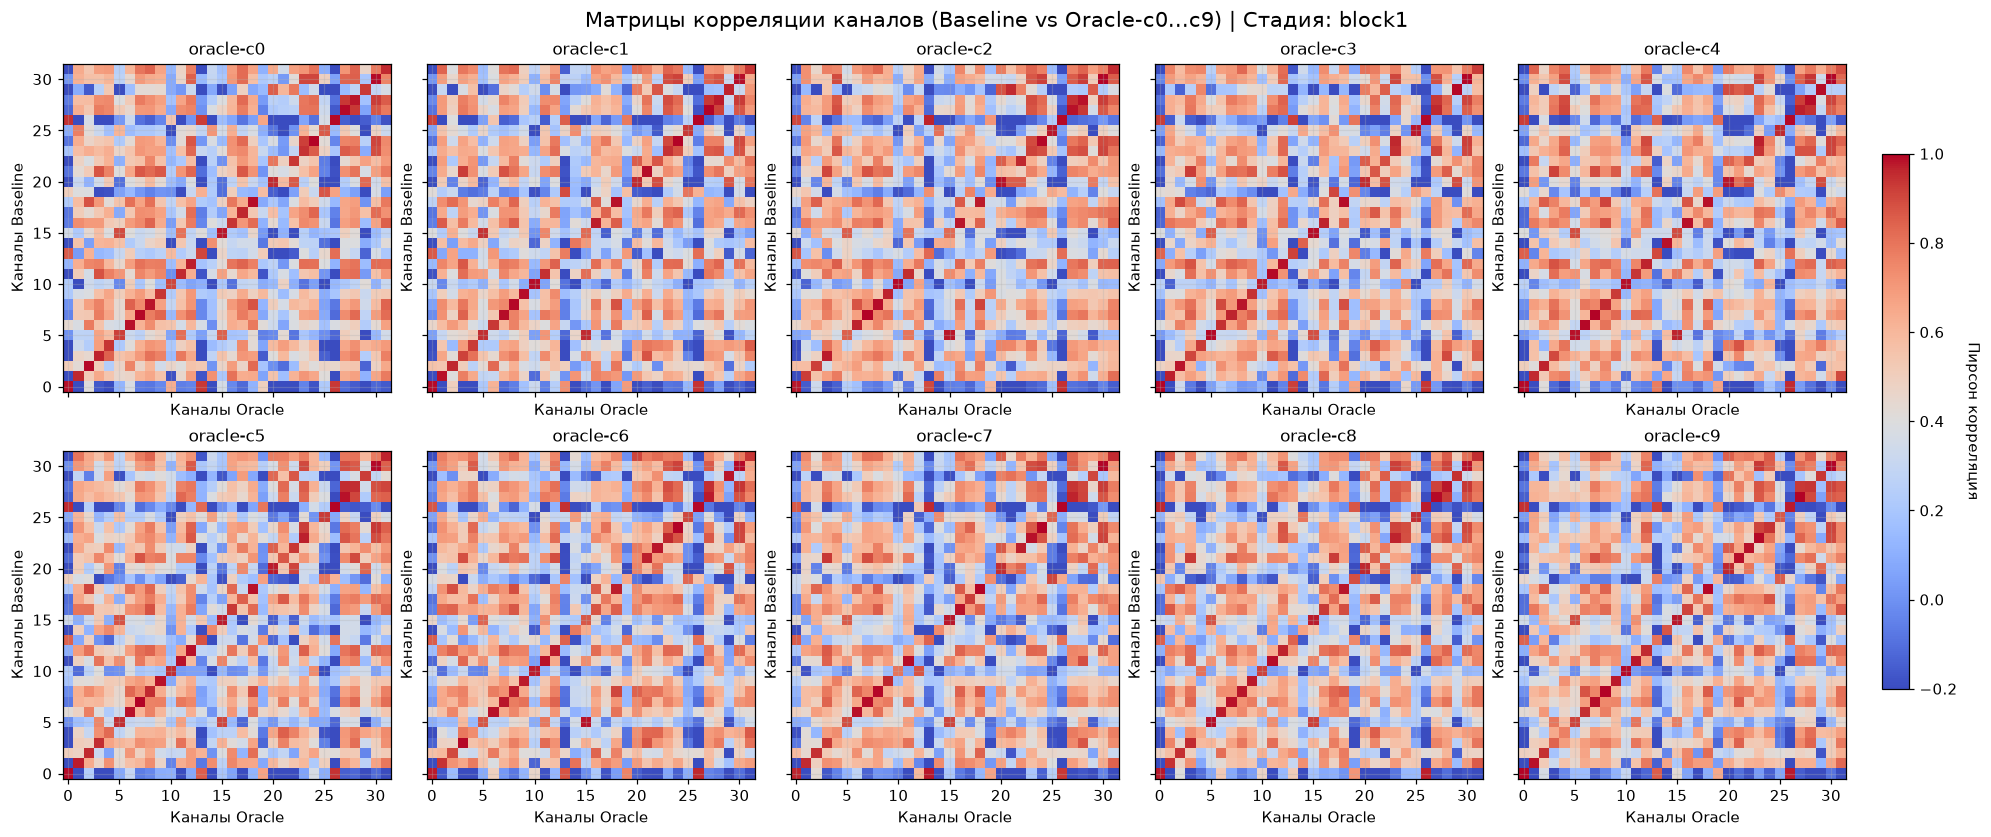

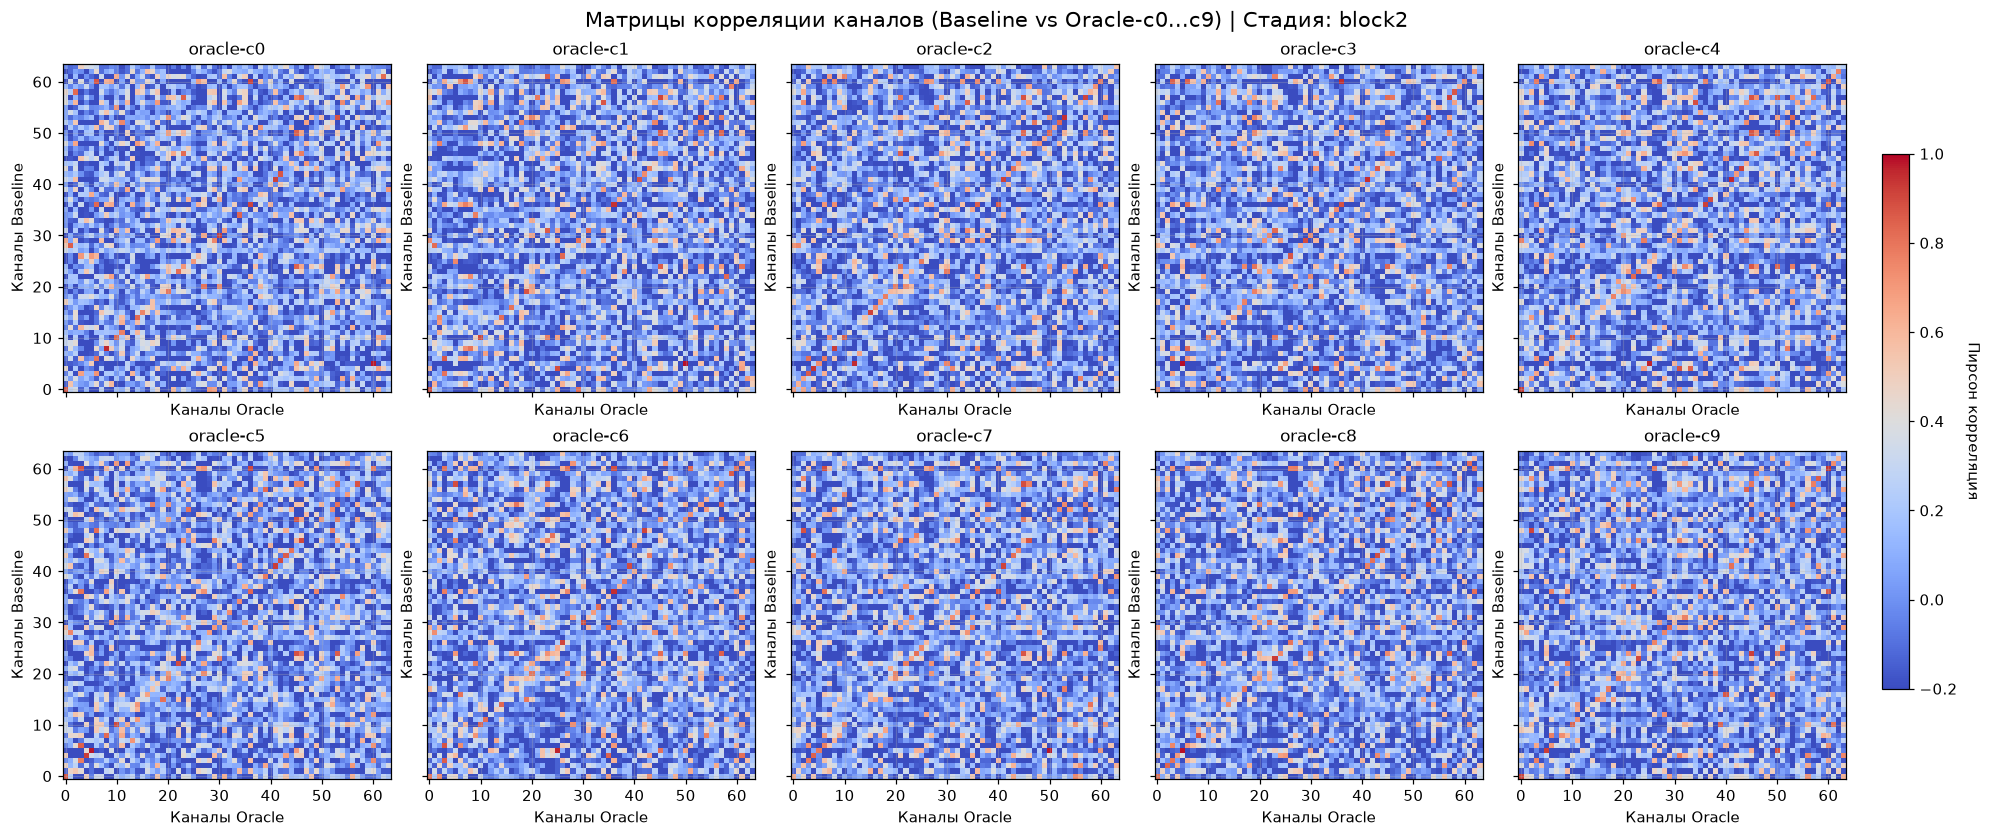

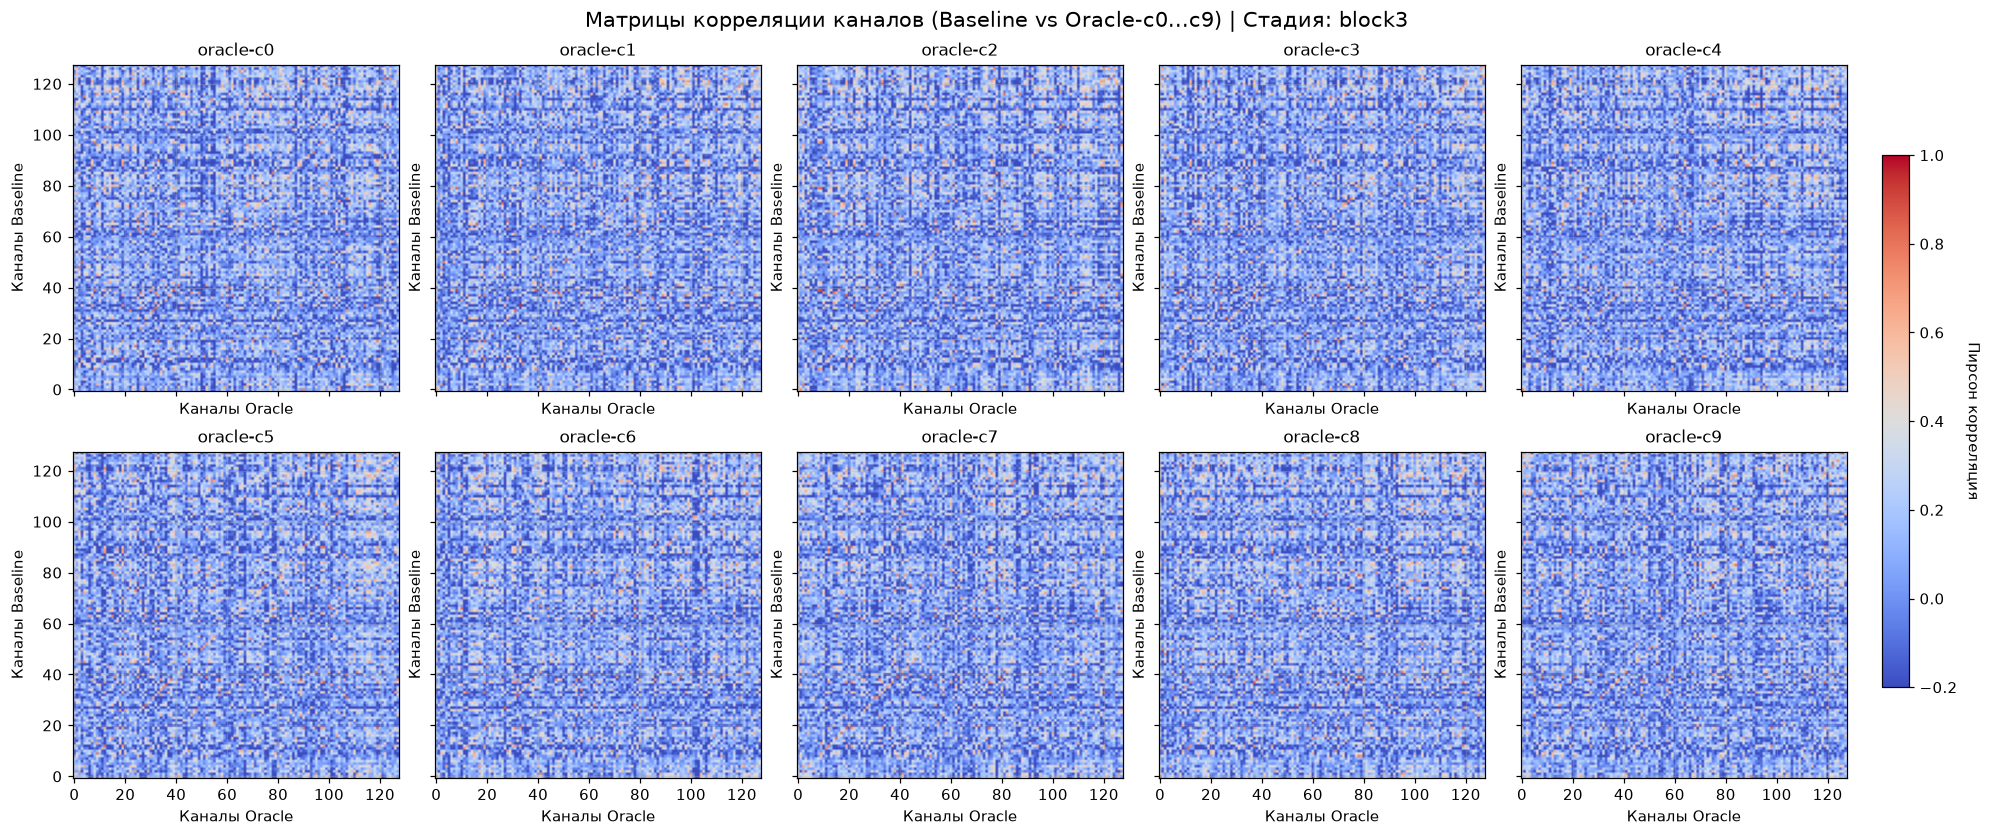

In [15]:
def channel_signatures(stage_features: torch.Tensor) -> torch.Tensor:
    return stage_features.mean(dim=(2, 3))


def channel_correlation_matrix(
    base_signature: torch.Tensor, oracle_signature: torch.Tensor
) -> torch.Tensor:
    a = base_signature - base_signature.mean(0, keepdim=True)
    b = oracle_signature - oracle_signature.mean(0, keepdim=True)
    a = a / (a.std(0, keepdim=True) + 1e-8)
    b = b / (b.std(0, keepdim=True) + 1e-8)
    return (a.T @ b) / len(a)


stages = ["block1", "block2", "block3"]
corr_matrices: dict[str, dict[int, torch.Tensor]] = {
    stage: {} for stage in stages
}
records = []

for stage in stages:
    base_sig = channel_signatures(features_by_model["baseline"][stage])
    num_channels = base_sig.shape[1]
    identity_indices = torch.arange(num_channels)

    for c in range(10):
        oracle_sig = channel_signatures(
            features_by_model[f"oracle-c{c}"][stage]
        )
        matrix = channel_correlation_matrix(base_sig, oracle_sig)
        corr_matrices[stage][c] = matrix

        diag_corr = float(torch.diag(matrix).mean())
        best = matrix.max(dim=1)
        best_corr = float(best.values.mean())
        rand_corr = float(matrix.mean())
        self_match = float((best.indices == identity_indices).float().mean())

        records.append(
            {
                "stage": stage,
                "oracle_class": c,
                "каналов": num_channels,
                "corr по тому же индексу": diag_corr,
                "corr лучшего партнера": best_corr,
                "corr случайной пары": rand_corr,
                "доля каналов, где лучший партнер - сам": self_match,
            }
        )

df_all = pd.DataFrame(records)

df_summary = (
    df_all.groupby("stage")[
        [
            "каналов",
            "corr по тому же индексу",
            "corr лучшего партнера",
            "corr случайной пары",
            "доля каналов, где лучший партнер - сам",
        ]
    ]
    .mean()
    .loc[stages]  # pyright: ignore[reportAttributeAccessIssue]
)

print("Средние метрики по всем 10 оракулам (сравнение с baseline):")
display(df_summary.round(3))


def plot_stage_correlation_matrices(
    stage_name: str, matrices_dict: dict[int, torch.Tensor]
):
    fig, axes = plt.subplots(
        2, 5, figsize=(18, 7.5), sharex=True, sharey=True, constrained_layout=True
    )
    fig.suptitle(
        f"Матрицы корреляции каналов (Baseline vs Oracle-c0...c9) | Стадия: {stage_name}",
        fontsize=14,
    )

    im = None
    for c in range(10):
        ax = axes[c // 5, c % 5]
        mat = matrices_dict[c].numpy()
        im = ax.imshow(mat, cmap="coolwarm", vmin=-0.2, vmax=1.0, origin="lower")
        if c == 9:
            cbar = fig.colorbar(
                im, ax=axes, orientation="vertical", fraction=0.015, pad=0.02
            )
            cbar.set_label("Пирсон корреляция", rotation=270, labelpad=15)
        ax.set_title(f"oracle-c{c}", fontsize=11)
        ax.set_xlabel("Каналы Oracle")
        ax.set_ylabel("Каналы Baseline")
    plt.show()


for stage in stages:
    plot_stage_correlation_matrices(stage, corr_matrices[stage])

Гипотеза о том, что веса в $S3$ разошлись из-за масштабирования в BatchNorm, не подтвердилась. Если бы каналы делали одно и то же, а BatchNorm просто поменял их масштаб и сдвиг, диагональная корреляция осталась бы близкой к $1.0$, но на самом деле корреляция по тому же индексу рухнула до $0.355$. Это доказывает что в `block3` произошло не просто масштабирование, а изменение исходного базиса каналов.

Глобальное функциональное сходство (Baseline vs Oracles):


,mean_cka,std_cka,min_cka,max_cka
stage,,,,
block1,0.9896,0.0026,0.9848,0.9936
block2,0.9664,0.0024,0.9609,0.9706
block3,0.9429,0.0019,0.9392,0.9452
embedding,0.9224,0.0128,0.8938,0.9374


[embedding] Средний CKA на забытом классе: 0.6890
[embedding] Средний CKA на сохраненных классах: 0.8125
Доля оракулов, где забытый класс дал минимальный CKA: 90.0%


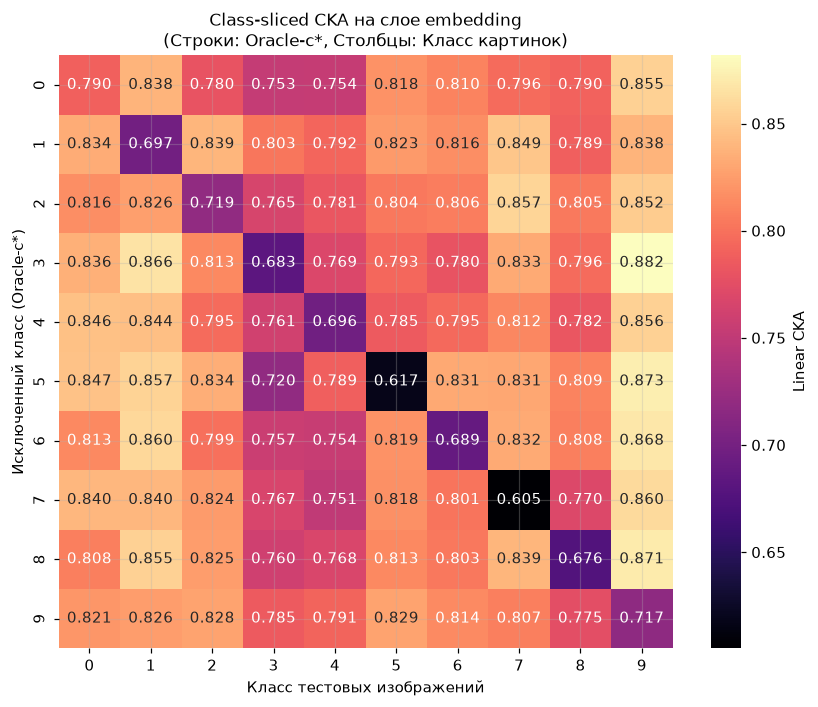

In [ ]:
def linear_cka(x: torch.Tensor, y: torch.Tensor) -> float:
    x = x.reshape(x.size(0), -1).float()
    y = y.reshape(y.size(0), -1).float()

    X_c = x - x.mean(dim=0, keepdim=True)
    Y_c = y - y.mean(dim=0, keepdim=True)

    K = X_c @ X_c.T
    L = Y_c @ Y_c.T

    hsic_xy = (K * L).sum()
    hsic_xx = (K * K).sum()
    hsic_yy = (L * L).sum()

    cka = hsic_xy / (torch.sqrt(hsic_xx * hsic_yy) + 1e-8)
    return float(cka.clamp(0.0, 1.0).item())

stages = ["block1", "block2", "block3", "embedding"]
global_cka_records = []

for stage in stages:
    base_feat = features_by_model["baseline"][stage]
    stage_scores = []
    for c in range(10):
        oracle_feat = features_by_model[f"oracle-c{c}"][stage]
        score = linear_cka(base_feat, oracle_feat)
        stage_scores.append(score)

    global_cka_records.append(
        {
            "stage": stage,
            "mean_cka": np.mean(stage_scores),
            "std_cka": np.std(stage_scores),
            "min_cka": np.min(stage_scores),
            "max_cka": np.max(stage_scores),
        }
    )

df_global_cka = pd.DataFrame(global_cka_records).set_index("stage")
print("Глобальное функциональное сходство (Baseline vs Oracles):")
display(df_global_cka.round(4))
target_stage = "embedding"
cka_class_matrix = np.zeros((10, 10))

base_feat_stage = features_by_model["baseline"][target_stage]

for c in range(10):
    oracle_feat_stage = features_by_model[f"oracle-c{c}"][target_stage]
    for k in range(10):
        mask = analysis_targets == k
        cka_class_matrix[c, k] = linear_cka(
            base_feat_stage[mask], oracle_feat_stage[mask]
        )

df_slice = pd.DataFrame(cka_class_matrix)
is_diagonal_min = [
    bool(cka_class_matrix[c, c] == cka_class_matrix[c].min()) for c in range(10)
]
diag_values = np.diag(cka_class_matrix)
off_diag_values = [
    cka_class_matrix[c, k]
    for c in range(10)
    for k in range(10)
    if c != k
]

print(f"[{target_stage}] Средний CKA на забытом классе: {diag_values.mean():.4f}")
print(
    f"[{target_stage}] Средний CKA на сохраненных классах: {np.mean(off_diag_values):.4f}"
)
print(f"Доля оракулов, где забытый класс дал минимальный CKA: {np.mean(is_diagonal_min)*100:.1f}%")

plt.figure(figsize=(9, 7))
sns.heatmap(
    df_slice,
    annot=True,
    fmt=".3f",
    cmap="magma",
    cbar_kws={"label": "Linear CKA"},
)
plt.title(
    f"Class-sliced CKA на слое {target_stage}\n(Строки: Oracle-c*, Столбцы: Класс картинок)"
)
plt.xlabel("Класс тестовых изображений")
plt.ylabel("Исключенный класс (Oracle-c*)")
plt.show()

В весовом анализе слой $S3$ показал большой разрыв с базой ($\text{rel\_dist} \approx 0.87$) и нулевую корреляцию со смыслом классов ($\rho \approx 0.0$), а совпадение каналов упало до $14.1\%$, но CKA у этого слоя $0.9429$ $\Rightarrow$ функционально блок 3 почти не меняется от модели к модели. Падение понейронных метрик и рост расстояния весов были вызваны перетасовкой каналов и сменой базиса в многомерном пространстве, а не тем, что оракул извлекает другие высокоуровневые признаки.

Поклассовый срез на слое embedding подтверждает наличие изолированного следа Machine Unlearning. Средний CKA на сохраненных классах составляет $0.8125$, а на забытом классе проседает до $0.6890$. У 90.0% оракулов минимальное значение CKA в строке приходится на тот класс, который был исключен из выборки, то есть максимальная разница в основном только на удаленных классах. На 9 классах, которые сеть должна помнить, сходство представлений с baseline удерживается в диапазоне $0.78–0.88$.

Сверточные стадии $S5, S4, S3$ (block1–block3) имеют CKA от $0.94$ до $0.99$. Они функционально универсальны. Алгоритмы Unlearning не должны модифицировать сверточные слои и вся специфика удаления класса должна быть сосредоточена на этапах $S2\_embedding$ и $S1\_logits$.

## Трансплантация слоев: перестановка стадий, клей и аналитическое выравнивание

Сверточные стадии почти не меняются от модели к модели
(CKA $0.94-0.99$; у `block1` совпадение каналов по индексу $0.92$, у `block3` - уже $0.36$), а голова
(`S1`, `S2`) меняется сильно (косинус весов $0.17-0.24$; на `embedding` CKA падает с $0.81$ на сохраненных
классах до $0.69$ на забытом). Отсюда три эксперимента:

1. **Прямая перестановка стадий** (обучения нет): переносим `S5` (самый похожий), затем `S4` и `S3`
   между моделями - из оракула в базу, из базы в оракул. Если стадия несет знание об
   удаленном классе, приемник начнет его забывать (или вспоминать); если стадия универсальна - поведение
   почти не изменится.
2. **Клей между стволом и головой**: базисы представлений у моделей не совпадают, поэтому прямой перенос
   весов головы не обязан работать. Ставим между замороженным стволом одной модели и замороженной головой
   другой обучаемый линейный слой: без клея, клей по МНК, дистилляция.
3. **Аналитическое выравнивание**: ортогональный Прокруст (`SVD`, без обучения) в пространстве признаков и
   перестановка каналов (жадное назначение + локальные обмены) для переноса сверточных стадий. Проверка
   гипотезы, что разница между моделями - это смена базиса, а не другой признак.

Контроли на каждом шаге: пустой набор стадий = приемник побитово, полный набор = источник побитово.

In [ ]:
WEIGHT_TO_ACTIVATION: dict[str, str] = {
    "S5_block1": "block1",
    "S4_block2": "block2",
    "S3_block3": "block3",
}


def with_stages(
    base_state: dict[str, torch.Tensor],
    source_state: dict[str, torch.Tensor],
    stages: list[str],
) -> dict[str, torch.Tensor]:
    keys = {key for stage in stages for key in STAGE_KEYS[stage]}
    return {
        key: (source_state[key].clone() if key in keys else value.clone())
        for key, value in base_state.items()
    }


def evaluation_on(
    name: str, logits: torch.Tensor, targets: npt.NDArray[np.int64]
) -> Evaluation:
    probability = torch.softmax(logits.float(), dim=-1).numpy().astype(np.float64)
    return Evaluation(
        name=name,
        probability=probability,
        prediction=logits.argmax(dim=-1).numpy().astype(np.int64),
        target=np.asarray(targets, dtype=np.int64),
    )


def state_evaluation(
    name: str,
    state: dict[str, torch.Tensor],
    loader: DataLoader[Any],
    targets: npt.NDArray[np.int64],
) -> Evaluation:
    return evaluation_on(name, collect_logits(build_model(state), loader), targets)


def state_summary(
    name: str,
    state: dict[str, torch.Tensor],
    forget_class: int = FORGET_CLASS,
) -> EvaluationSummary:
    return summarize(
        state_evaluation(name, state, analysis_loader, analysis_targets), forget_class
    )


def distribution_distance(
    left: npt.NDArray[np.float64], right: npt.NDArray[np.float64]
) -> float:
    return float(np.linalg.norm(left - right) / np.linalg.norm(right))

subset_reference: dict[str, npt.NDArray[np.float64]] = {
    name: evaluation_on(
        name, collect_logits(data.model, analysis_loader), analysis_targets
    ).probability
    for name, data in tqdm(MODELS.items(), desc="эталонные распределения")
}

SCAN_PER_CLASS: Final[int] = 30
scan_rng = np.random.default_rng(SEED)
scan_indices = np.sort(
    np.concatenate(
        [
            scan_rng.choice(
                np.where(test_targets == cls)[0], SCAN_PER_CLASS, replace=False
            )
            for cls in range(10)
        ]
    )
)
scan_targets = test_targets[scan_indices]
scan_loader = DataLoader(
    Subset(test_raw, scan_indices.tolist()), batch_size=256, shuffle=False
)
scan_reference: dict[str, npt.NDArray[np.float64]] = {
    name: evaluation_on(
        name, collect_logits(data.model, scan_loader), scan_targets
    ).probability
    for name, data in MODELS.items()
}


def scan_evaluation(name: str, state: dict[str, torch.Tensor]) -> Evaluation:
    return state_evaluation(name, state, scan_loader, scan_targets)

oracle_c0_state: dict[str, torch.Tensor] = MODELS[f"oracle-c{FORGET_CLASS}"].state
baseline_subset_logits = collect_logits(baseline.model, analysis_loader)
oracle_c0_subset_logits = collect_logits(
    MODELS[f"oracle-c{FORGET_CLASS}"].model, analysis_loader
)
assert torch.equal(
    collect_logits(
        build_model(with_stages(baseline_state, oracle_c0_state, [])), analysis_loader
    ),
    baseline_subset_logits,
), "пустой набор стадий должен совпадать с base побитово"
assert torch.equal(
    collect_logits(
        build_model(with_stages(baseline_state, oracle_c0_state, STAGE_ORDER)),
        analysis_loader,
    ),
    oracle_c0_subset_logits,
), "полный набор стадий должен совпадать с oracle побитово"
assert torch.equal(
    collect_logits(
        build_model(with_stages(oracle_c0_state, baseline_state, [])), analysis_loader
    ),
    oracle_c0_subset_logits,
), "пустой набор стадий в обратную сторону должен совпадать с приемником"
print("Контроли сошлись: 0 стадий = приемник, все 5 стадий = источник (побитово).")

эталонные распределения: 100%|██████████| 11/11 [00:30<00:00,  2.79s/it]


Контроли сошлись: 0 стадий = приемник, все 5 стадий = источник (побитово).


### 1. Прямая перестановка стадий

Берем модель-приемник и подменяем в ней тензоры одной стадии тензорами модели-источника. Ничего не обучаем.

| вариант | приемник | источник | что означало бы «стадия несет знание о классе» |
| :--- | :--- | :--- | :--- |
| `base <- oracle-c0` | `baseline` | `oracle-c0` | база начинает забывать класс 0 |
| `oracle-c0 <- base` | `oracle-c0` | `baseline` | забывание класса 0 пропадает |
| `oracle-cj <- oracle-ci` | `oracle-cj` | `oracle-ci` | приемник сдвигается к источнику на его классе |

Считаем `S5_block1`, `S4_block2` и `S3_block3` (по весам расходится сильнее
всего) и их комбинацию. Метрики на общей подвыборке 1500 изображений, а рядом лежат расстояния
распределений до `base` и до источника: они показывают, к какому родителю вариант ближе.

перенос стадий: 100%|██████████| 4/4 [00:36<00:00,  9.22s/it]

Перестановка стадий без обучения:


,стадии,направление,retain_accuracy,accuracy_forget_class,p_forget_class,collapse_class,d_to_base,d_to_source
0,-,base (эталон),0.8393,0.8600,0.8119,ship,0.0000,NaN
1,-,oracle-c0 (эталон),0.8607,0.0000,0.0000,ship,NaN,0.0000
2,S5_block1,base <- oracle-c0,0.7519,0.8733,0.7710,ship,0.3778,0.5826
3,S5_block1,oracle-c0 <- base,0.7859,0.0000,0.0000,ship,0.5663,0.5663
4,S4_block2,base <- oracle-c0,0.4319,0.5867,0.4738,cat,0.8175,0.8643
5,S4_block2,oracle-c0 <- base,0.4630,0.0000,0.0000,bird,0.8825,0.8825
6,S5_block1+S4_block2,base <- oracle-c0,0.4741,0.4800,0.4021,automobile,0.8039,0.8403
7,S5_block1+S4_block2,oracle-c0 <- base,0.5281,0.0000,0.0000,bird,0.8262,0.8262
8,S3_block3,base <- oracle-c0,0.4556,0.2400,0.2342,ship,0.8230,0.8193
9,S3_block3,oracle-c0 <- base,0.4126,0.0000,0.0000,ship,0.9034,0.9034


base <- oracle-c* (S4_block2): 100%|██████████| 10/10 [00:04<00:00,  2.21it/s]


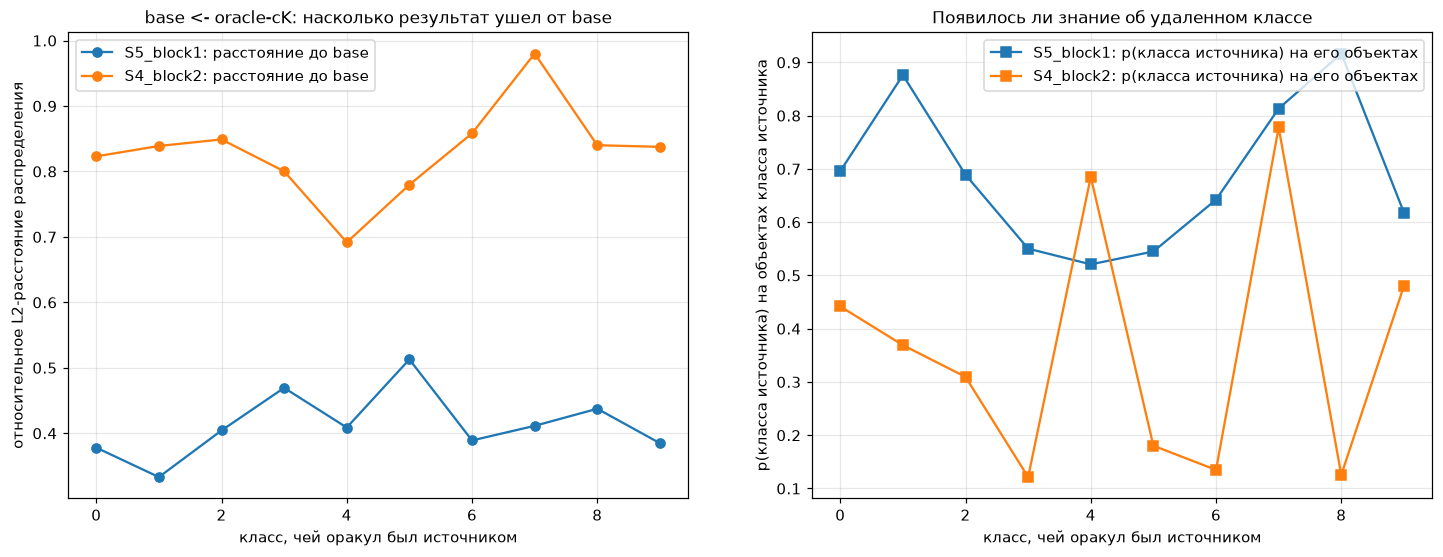

Специфичность переноса (средние по оракулам):


,p_source_class,d_to_base,d_to_source
стадии,,,
S4_block2,0.3625,0.8299,0.8535
S5_block1,0.6867,0.4129,0.5758


In [ ]:
TRANSPLANT_SETS: list[tuple[str, ...]] = [
    ("S5_block1",),
    ("S4_block2",),
    ("S5_block1", "S4_block2"),
    ("S3_block3",),
]
DIRECTIONS: list[tuple[str, str, str]] = [
    ("base <- oracle-c0", "baseline", f"oracle-c{FORGET_CLASS}"),
    (f"oracle-c{FORGET_CLASS} <- base", f"oracle-c{FORGET_CLASS}", "baseline"),
]

transplant_rows: list[dict[str, Any]] = []
for name, state in (
    ("base (эталон)", baseline_state),
    (f"oracle-c{FORGET_CLASS} (эталон)", oracle_c0_state),
):
    summary = state_summary(name, state)
    transplant_rows.append(
        {
            "стадии": "-",
            "направление": name,
            "retain_accuracy": summary.retain_accuracy,
            "accuracy_forget_class": summary.accuracy_forget_class,
            "p_forget_class": summary.confidence_forget_class,
            "collapse_class": CLASS_NAMES[summary.collapse_class],
            "d_to_base": 0.0 if name.startswith("base") else np.nan,
            "d_to_source": 0.0 if not name.startswith("base") else np.nan,
        }
    )

for stages in tqdm(TRANSPLANT_SETS, desc="перенос стадий"):
    stage_label = "+".join(stages)
    for label, target_name, source_name in DIRECTIONS:
        state = with_stages(
            MODELS[target_name].state, MODELS[source_name].state, list(stages)
        )
        summary = state_summary(f"{stage_label}: {label}", state)
        probability = state_evaluation(
            f"{stage_label}: {label}", state, analysis_loader, analysis_targets
        ).probability
        transplant_rows.append(
            {
                "стадии": stage_label,
                "направление": label,
                "retain_accuracy": summary.retain_accuracy,
                "accuracy_forget_class": summary.accuracy_forget_class,
                "p_forget_class": summary.confidence_forget_class,
                "collapse_class": CLASS_NAMES[summary.collapse_class],
                "d_to_base": distribution_distance(
                    probability, subset_reference["baseline"]
                ),
                "d_to_source": distribution_distance(
                    probability, subset_reference[source_name]
                ),
            }
        )

transplant = pd.DataFrame(transplant_rows)
print("Перестановка стадий без обучения:")
display(transplant.round(4))

specificity_rows: list[dict[str, Any]] = []
for stages in (("S5_block1",), ("S4_block2",)):
    stage_label = "+".join(stages)
    for cls in tqdm(CANDIDATES, desc=f"base <- oracle-c* ({stage_label})"):
        source_name = f"oracle-c{cls}"
        state = with_stages(baseline_state, MODELS[source_name].state, list(stages))
        probability = state_evaluation(
            f"{stage_label}: base <- {source_name}", state, scan_loader, scan_targets
        ).probability
        specificity_rows.append(
            {
                "стадии": stage_label,
                "source_class": cls,
                "p_source_class": float(
                    np.mean(probability[scan_targets == cls, cls])
                ),
                "d_to_base": distribution_distance(
                    probability, scan_reference["baseline"]
                ),
                "d_to_source": distribution_distance(
                    probability, scan_reference[source_name]
                ),
            }
        )
specificity = pd.DataFrame(specificity_rows)

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(16, 5.5))
for stages in (("S5_block1",), ("S4_block2",)):
    stage_label = "+".join(stages)
    selection = specificity[specificity["стадии"] == stage_label]
    ax_left.plot(
        selection["source_class"],
        selection["d_to_base"],
        marker="o",
        label=f"{stage_label}: расстояние до base",
    )
    ax_right.plot(
        selection["source_class"],
        selection["p_source_class"],
        marker="s",
        label=f"{stage_label}: p(класса источника) на его объектах",
    )
ax_left.set_xlabel("класс, чей оракул был источником")
ax_left.set_ylabel("относительное L2-расстояние распределения")
ax_left.set_title("base <- oracle-cK: насколько результат ушел от base")
ax_left.legend()
ax_right.set_xlabel("класс, чей оракул был источником")
ax_right.set_ylabel("p(класса источника) на объектах класса источника")
ax_right.set_title("Появилось ли знание об удаленном классе")
ax_right.legend()
plt.show()

print("Специфичность переноса (средние по оракулам):")
display(
    specificity.groupby("стадии")[["p_source_class", "d_to_base", "d_to_source"]]
    .mean()
    .round(4)
)

Сеть выдерживает прямую пересадку $S5$ с сохранением $\approx 75–79\%$ точности. Это подтверждает ранний вывод: низкоуровневые детекторы жестко зафиксированы начальным сидом и одинаковы у всех моделей. В $S5$ нет информации о принадлежности к классу: пересадка $S5$ из оракула в базу не снижает точность на забываемом классе ($87.3\%$ против $86.0\%$ у базы), а пересадка из базы в оракул не возвращает его ($0.0\%$) $\Rightarrow$ $S5$ не участвует в процессе забывания. Затрагивать его веса алгоритмами Unlearning бессмысленно.

При попытке пересадить $S4$ или $S3$ точность модели падает с $84\%$ до $41–46\%$. Это доказывает вывод из анализа корреляций каналов: в блоках $S4$ и $S3$ произошла перестановка каналов и смена координатного базиса и если взять сырой тензор $S4$ оракула и вставить его в базу, то получится так, что следующий блок ожидает старую раскладку признаков по каналам, а получает перемешанные. Происходит внутренний рассинхрон представлений, разрушающий прямой проход.

### 2. Клей: обучаемый линейный слой между стволом и головой

Раздел 1 показывает: сверточные стадии можно переносить, но забывание при этом не переносится. Раздел CKA
показывает другое: `S2_embedding` и `S1_logits` меняются сильно, а веса головы `base` и `oracle` почти
ортогональны (косинус $0.17-0.24$). Значит, прямой перенос весов головы бессмыслен: базисы разные.

Проверяем, можно ли не переносить веса, а сшить модели: ствол одной модели заморожен, голова другой
заморожена, между ними обучаемый линейный слой.

Варианты:

| вариант | что делает клей |
| :--- | :--- |
| без клея (`Identity`) | контроль: признаки base идут прямо в голову oracle |
| клей по МНК (`ridge`) | закрытая форма $G = (A^T A + \lambda I)^{-1} A^T B$: линейное отображение признаков base в признаки oracle |
| клей Прокруста | то же, что и МНК, но с ортогональным ограничением $R^T R = I$  |
| клей на дистилляции | клей учится так, чтобы голова oracle на признаках base повторяла oracle |
| то же со стартом с МНК | дообучение начинается не с единичной матрицы, а с решения МНК - проверка, добавляет ли дистилляция что-то к закрытой форме |

Срез выбирается в двух местах: `split=1` - сразу после `Flatten` (2048 признаков), `split=3` - в embedding
(128 признаков, после `Linear(2048->128)` и `ReLU` головы oracle).

In [25]:
FLATTEN_MODULE: Final[str] = "head.0"
GLUE_SPLITS: tuple[tuple[int, int], ...] = ((1, 2048), (3, 128))
RETAIN_TRAIN_SIZE: Final[int] = 13500


@torch.no_grad()
def collect_flatten(model: nn.Module, loader: DataLoader[Any]) -> torch.Tensor:
    """2048-мерные признаки на входе головы (выход Flatten) для всего загрузчика."""
    store: list[torch.Tensor] = []
    handle = model.get_submodule(FLATTEN_MODULE).register_forward_hook(
        lambda module, inputs, output: store.append(output.detach().cpu())
    )
    for x, _ in loader:
        model(x.to(device))
    handle.remove()
    return torch.cat(store)


class GlueHead(nn.Module):
    """Голова модели-источника с линейным «клеем»: split=1 - на входе головы, split=3 - в embedding.

    На вход подаются уже развернутые признаки (выход Flatten), поэтому Flatten из головы исключен.
    """

    def __init__(
        self, head_state: dict[str, torch.Tensor], split: int, glue: nn.Module
    ) -> None:
        super().__init__()
        modules = list(build_model(head_state).head)[1:]
        self.before: nn.Module = nn.Sequential(*modules[: split - 1])
        self.glue: nn.Module = glue
        self.after: nn.Module = nn.Sequential(*modules[split - 1 :])
        for module in (self.before, self.after):
            for parameter in module.parameters():
                parameter.requires_grad_(False)

    @override
    def forward(self, flattened: torch.Tensor) -> torch.Tensor:
        return self.after(self.glue(self.before(flattened)))


@torch.no_grad()
def glue_logits(
    head_state: dict[str, torch.Tensor],
    split: int,
    glue: nn.Module,
    flattened: torch.Tensor,
) -> torch.Tensor:
    """Логиты сшитой модели на готовых признаках (для замеров; параметры клея градиентов не требуют)."""
    return GlueHead(head_state, split, glue).eval()(flattened)


def seam_features(
    flattened: torch.Tensor, head_state: dict[str, torch.Tensor], split: int
) -> torch.Tensor:
    """Признаки на срезе: то, что подается на клей (для split=1 это сам вход головы)."""
    modules = list(build_model(head_state).head)[1:]
    with torch.no_grad():
        return nn.Sequential(*modules[: split - 1])(flattened)


def identity_glue(dim: int) -> nn.Linear:
    glue = nn.Linear(dim, dim)
    with torch.no_grad():
        glue.weight.copy_(torch.eye(dim))
        glue.bias.zero_()
    return glue


def ridge_glue(
    source: torch.Tensor, target: torch.Tensor, ridge: float = 1.0
) -> tuple[nn.Linear, float]:
    """Клей по МНК (закрытая форма): G = argmin ||A G^T + b - B||^2 + ridge * ||G||^2."""
    a, b = source.double(), target.double()
    a_mean, b_mean = a.mean(0, keepdim=True), b.mean(0, keepdim=True)
    a_centered, b_centered = a - a_mean, b - b_mean
    gram = a_centered.T @ a_centered + ridge * torch.eye(
        a_centered.shape[1], dtype=torch.float64
    )
    weight = torch.linalg.solve(gram, a_centered.T @ b_centered)
    glue = nn.Linear(a_centered.shape[1], b_centered.shape[1])
    with torch.no_grad():
        glue.weight.copy_(weight.T.float())
        glue.bias.copy_((b_mean - a_mean @ weight).flatten().float())
    residual = float((a_centered @ weight - b_centered).norm() / b_centered.norm())
    return glue, residual


def procrustes_glue(
    source: torch.Tensor, target: torch.Tensor
) -> tuple[nn.Linear, float]:
    """Ортогональный Прокруст: R = argmin по R^T R = I от ||A R - B||, решение R = U V^T из SVD(A^T B)."""
    a, b = source.double(), target.double()
    a_mean, b_mean = a.mean(0, keepdim=True), b.mean(0, keepdim=True)
    a_centered, b_centered = a - a_mean, b - b_mean
    u, _, vh = torch.linalg.svd(a_centered.T @ b_centered, full_matrices=False)
    rotation = u @ vh
    glue = nn.Linear(a_centered.shape[1], b_centered.shape[1])
    with torch.no_grad():
        glue.weight.copy_(rotation.T.float())
        glue.bias.copy_((b_mean - a_mean @ rotation).flatten().float())
    residual = float((a_centered @ rotation - b_centered).norm() / b_centered.norm())
    return glue, residual


def fit_glue_distillation(
    head_state: dict[str, torch.Tensor],
    split: int,
    dim: int,
    source_features: torch.Tensor,
    teacher_logits: torch.Tensor,
    epochs: int = 15,
    batch_size: int = 256,
    learning_rate: float = 1e-3,
    initial: nn.Linear | None = None,
) -> tuple[GlueHead, list[float]]:
    """Дообучение клея на дистилляции: голова oracle на признаках base повторяет вероятности oracle.

    initial - готовый клей (например, решение МНК), с которого начинается дообучение.
    """
    set_seed(SEED)
    model = GlueHead(head_state, split, identity_glue(dim)).eval()
    if initial is not None:
        with torch.no_grad():
            model.glue.weight.copy_(initial.weight)
            model.glue.bias.copy_(initial.bias)
    optimizer = optim.AdamW(model.glue.parameters(), lr=learning_rate, weight_decay=1e-4)
    teacher_probability = torch.softmax(teacher_logits.float(), dim=-1)
    loader = DataLoader(
        torch.utils.data.TensorDataset(source_features.float(), teacher_probability),
        batch_size=batch_size,
        shuffle=True,
    )
    losses: list[float] = []
    for _ in range(epochs):
        total = 0.0
        for x, y in loader:
            optimizer.zero_grad()
            loss = nn.functional.kl_div(
                torch.log_softmax(model(x), dim=-1), y, reduction="batchmean"
            )
            loss.backward()
            optimizer.step()
            total += float(loss.detach()) * len(x)
        losses.append(total / len(source_features))
    model.eval()
    return model, losses


retain_train_indices = np.where(
    np.array(train_raw_deterministic.targets) != FORGET_CLASS
)[0]
retain_train_rng = np.random.default_rng(SEED)
retain_train_sample = np.sort(
    retain_train_rng.choice(retain_train_indices, size=RETAIN_TRAIN_SIZE, replace=False)
)
retain_train_loader = DataLoader(
    Subset(train_raw_deterministic, retain_train_sample.tolist()),
    batch_size=256,
    shuffle=False,
)

oracle_model = MODELS[f"oracle-c{FORGET_CLASS}"].model
base_train_flatten = collect_flatten(baseline.model, retain_train_loader)
oracle_train_flatten = collect_flatten(oracle_model, retain_train_loader)
oracle_train_logits = collect_logits(oracle_model, retain_train_loader)
base_test_flatten = collect_flatten(baseline.model, test_loader)
oracle_test_flatten = collect_flatten(oracle_model, test_loader)
print(
    "Признаки на срезе Flatten: обучение",
    tuple(base_train_flatten.shape),
    "| тест",
    tuple(base_test_flatten.shape),
)

identity_control = glue_logits(baseline_state, 1, identity_glue(2048), base_test_flatten)
assert np.allclose(
    torch.softmax(identity_control.float(), dim=-1).numpy(),
    evaluations["baseline"].probability,
    atol=1e-6,
), "identity-клей должен повторять исходную модель"
print("Контроль сошелся: ствол base + голова base + identity-клей = base.")

Признаки на срезе Flatten: обучение (13500, 2048) | тест (10000, 2048)
Контроль сошелся: ствол base + голова base + identity-клей = base.


In [29]:
stitch_rows: list[dict[str, Any]] = []
for label, flatten, head_state in (
    ("base (ствол base + голова base)", base_test_flatten, baseline_state),
    (
        f"oracle-c{FORGET_CLASS} (ствол oracle + голова oracle)",
        oracle_test_flatten,
        oracle_c0_state,
    ),
):
    logits = glue_logits(head_state, 1, identity_glue(2048), flatten)
    summary = summarize(build_evaluation(label, logits), forget_class=FORGET_CLASS)
    probability = torch.softmax(logits.float(), dim=-1).numpy()
    stitch_rows.append(
        {
            "вариант": label,
            "срез": "-",
            "residual": np.nan,
            "retain_accuracy": summary.retain_accuracy,
            "accuracy_forget_class": summary.accuracy_forget_class,
            "confidence_forget_class": summary.confidence_forget_class,
            "d_to_base": distribution_distance(
                probability, evaluations["baseline"].probability
            ),
            "d_to_source": distribution_distance(
                probability, evaluations[f"oracle-c{FORGET_CLASS}"].probability
            ),
        }
    )

for split, dim in GLUE_SPLITS:
    source_seam_train = seam_features(base_train_flatten, oracle_c0_state, split)
    target_seam_train = seam_features(oracle_train_flatten, oracle_c0_state, split)
    ridge, ridge_residual = ridge_glue(source_seam_train, target_seam_train)
    rotation, rotation_residual = procrustes_glue(source_seam_train, target_seam_train)
    distilled, distillation_losses = fit_glue_distillation(
        oracle_c0_state, split, dim, base_train_flatten, oracle_train_logits
    )
    warmed, warmed_losses = fit_glue_distillation(
        oracle_c0_state,
        split,
        dim,
        base_train_flatten,
        oracle_train_logits,
        initial=ridge,
    )
    print(
        f"срез split={split} ({dim}): остаток МНК {ridge_residual:.4f}, "
        f"ортогональный остаток {rotation_residual:.4f}, "
        f"KL после дистилляции {distillation_losses[-1]:.5f}, "
        f"со стартом с МНК {warmed_losses[-1]:.5f}"
    )

    for name, glue, residual in (
        ("без клея (identity)", nn.Identity(), np.nan),
        ("клей по МНК (ridge)", ridge, ridge_residual),
        ("клей Прокруста (ортогональный)", rotation, rotation_residual),
        ("клей на дистилляции", distilled.glue, np.nan),
        ("клей на дистилляции (старт с МНК)", warmed.glue, np.nan),
    ):
        logits = glue_logits(oracle_c0_state, split, glue, base_test_flatten)
        summary = summarize(build_evaluation(name, logits), forget_class=FORGET_CLASS)
        probability = torch.softmax(logits.float(), dim=-1).numpy()
        stitch_rows.append(
            {
                "вариант": f"base features + {name} + oracle head",
                "срез": f"split={split} ({dim})",
                "residual": residual,
                "retain_accuracy": summary.retain_accuracy,
                "accuracy_forget_class": summary.accuracy_forget_class,
                "confidence_forget_class": summary.confidence_forget_class,
                "d_to_base": distribution_distance(
                    probability, evaluations["baseline"].probability
                ),
                "d_to_source": distribution_distance(
                    probability, evaluations[f"oracle-c{FORGET_CLASS}"].probability
                ),
            }
        )

stitching = pd.DataFrame(stitch_rows)
print("Сшивка: ствол base + клей + голова oracle (и контроли):")
display(stitching.round(4))

срез split=1 (2048): остаток МНК 0.4249, ортогональный остаток 0.5450, KL после дистилляции 0.06960, со стартом с МНК 0.06106
срез split=3 (128): остаток МНК 0.5885, ортогональный остаток 0.6772, KL после дистилляции 0.41917, со стартом с МНК 0.41761
Сшивка: ствол base + клей + голова oracle (и контроли):


,вариант,срез,residual,retain_accuracy,accuracy_forget_class,confidence_forget_class,d_to_base,d_to_source
0,base (ствол base + голова base),-,NaN,0.8298,0.881,0.8187,0.0000,0.4857
1,oracle-c0 (ствол oracle + голова oracle),-,NaN,0.8450,0.000,0.0000,0.4853,0.0000
2,base features + без клея (identity) + oracle head,split=1 (2048),NaN,0.5889,0.000,0.0000,0.7485,0.6808
3,base features + клей по МНК (ridge) + oracle head,split=1 (2048),0.4249,0.8301,0.000,0.0000,0.4578,0.2511
4,base features + клей Прокруста (ортогональный)...,split=1 (2048),0.5450,0.8280,0.000,0.0000,0.4541,0.2799
5,base features + клей на дистилляции + oracle head,split=1 (2048),NaN,0.8102,0.000,0.0000,0.4789,0.3340
6,base features + клей на дистилляции (старт с М...,split=1 (2048),NaN,0.8111,0.000,0.0000,0.4762,0.3157
7,base features + без клея (identity) + oracle head,split=3 (128),NaN,0.5889,0.000,0.0000,0.7485,0.6808
8,base features + клей по МНК (ridge) + oracle head,split=3 (128),0.5885,0.6857,0.000,0.0000,0.6476,0.5519
9,base features + клей Прокруста (ортогональный)...,split=3 (128),0.6772,0.6457,0.000,0.0000,0.6806,0.6040


1) При прямом насаживании головы оракула на ствол базы точность рушится на 25%. Это прямое следствие несовпадения координатных осей, выявленного на этапе анализа каналов.
2) Сверточный ствол базы не требует переобучения для Unlearning. Разница между выходом сверток базовой модели и оракула носит линейный характер. Достаточно одной матрицы, чтобы перевести признаки базовой модели на язык оракула.
3) Ортогональный Прокруст (жесткий поворот без обучения) показал результат $0.8280$. Представления признаков базы и оракула не сжаты и не деформированы относительно друг друга - они просто повернуты в пространстве.
4) Срез 128 сработал плохо по сравнению со срезом 2048.

## Итог
Если в процедуре Unlearning сохранять сверточный ствол базы неизменным, модель можно привести к состоянию оракула только оптимизацией головы, начиная с точки входа $2048$ (первый линейный слой).

Любая попытка аппроксимировать оракул через коррекцию только финального слоя логитов (128 -> 10) неизбежно потеряет в точности (до 10–12% падения качества).